In [1]:
#@title Import Dependencies

import torch
import torch.nn as nn
import torchvision.datasets as dsets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

%matplotlib inline

In [2]:
#@title Function to plot an image with the scale color bar
def plotWithColor(data):
  if torch.is_tensor(data):
    data=data.cpu().detach().numpy()
  ax = plt.subplot()
  im = ax.imshow(data)
  divider = make_axes_locatable(ax)
  cax = divider.append_axes("right", size="5%", pad=0.05)

  plt.colorbar(im, cax=cax)

  plt.show()

In [3]:
#@title Access MNIST data

# train_data = dsets.MNIST(root = '/content/gdrive/My Drive/Colab Models/', train = True,
#                         transform = transforms.ToTensor(), download = False)

# test_data = dsets.MNIST(root =  '/content/gdrive/My Drive/Colab Models/', train = False,
#                        transform = transforms.ToTensor(), download = False)


# train_data = dsets.MNIST(root='./data/', train=True, download=True, transform=transforms.ToTensor())
# test_data = dsets.MNIST(root='./data/', train=False, download=True, transform=transforms.ToTensor())

train_data = dsets.MNIST(root = './data', train = True,
                        transform = transforms.ToTensor(), download = True)

test_data = dsets.MNIST(root = './data', train = False,
                       transform = transforms.ToTensor())

In [4]:
#@title Loading the data

batch_size = 500 # the size of input data took for one iteration

train_gen = torch.utils.data.DataLoader(dataset = train_data,
                                             batch_size = batch_size,
                                             shuffle = True)

test_gen = torch.utils.data.DataLoader(dataset = test_data,
                                      batch_size = batch_size,
                                      shuffle = True)

In [5]:
#@title Define Hyperparameters

input_size = 784    # img_size = (28,28) ---> 28*28=784 in total
num_classes = 10    # number of output classes discrete range [0,9]
num_epochs = 50      # 20 # number of times which the entire dataset is passed throughout the model
lr = 1e-2           # size of step

In [6]:
#@title Function to randomize the task to do by flipping from digit to 9-digit
# this function takes an MNIST dataset as arguments (images and labels)
# it then randomizes if the goal is to return the digit or 9-digit for each image
# in the dataset.  It codes the right answer into the first two pixels of the image
def applyRandomFlip(images, labels, setAll=False, setValue=0):
  images_flip=images.clone()
  labels_flip=labels.clone()
  if setAll: # set all the values to the optional parameter setValue
    randFlips=None
    if setValue==0:
      images_flip[:,0]=1
      images_flip[:,1]=0
    else:
      labels_flip=9-labels_flip
      images_flip[:,0]=0
      images_flip[:,1]=1
  else:
    randFlips=torch.randint(0, 2, (images_flip.shape[0],))
    labels_flip[randFlips==1]=9-labels_flip[randFlips==1]
    images_flip[randFlips==1,0]=0
    images_flip[randFlips==1,1]=1
    images_flip[randFlips==0,0]=1
    images_flip[randFlips==0,1]=0

  return images_flip, labels_flip, randFlips



In [7]:
#@title Define Dendrite Hyperparameters

soma_n=10

excitatory_synapses_per_dendrite=24
inhibitory_synapses_per_dendrite=1

dendrite_branch_per_dendrite=2
dendrite_per_soma=1

dendrite_branch_per_soma=dendrite_branch_per_dendrite*dendrite_per_soma

e_i_ratio=excitatory_synapses_per_dendrite/inhibitory_synapses_per_dendrite
syn_to_dendrite_ratio=2*excitatory_synapses_per_dendrite/dendrite_branch_per_dendrite

inhibitory_units_n=20
synapses_per_inhibitory_unit=200

dendrite_n=soma_n*dendrite_per_soma
dendrite_branch_n=dendrite_n*dendrite_branch_per_dendrite

random_flip=False


In [8]:
#@title Define layer class that only keeps K top weights
class TopKLinear(nn.Linear):
  """ Custom Linear layer that only uses the stongest K weights """
  def __init__(self, in_features, out_features, keep_in_features, bias=False):
    super().__init__(in_features, out_features, bias=bias)
    self.keep_in_features = keep_in_features
    self.topk_indices=[]
    self.mask=0*self.weight.data
    self.net_weight=0*self.weight.data

  def forward(self, x):
    self.mask=0*self.weight.data
    self.topk_indices=torch.topk(self.weight, self.keep_in_features, 1, largest=True)[1]
    self.mask[torch.arange(self.weight.shape[0])[:,None], self.topk_indices] = 1  ##  Change those values to 1
    self.net_weight=self.mask*self.weight
    w_times_x= torch.mm(x, self.net_weight.t())
    return w_times_x


In [9]:
from math import floor
#@title Define layer class that uses a block structure
class BlockLinear(nn.Linear):
  """ Custom Linear layer that only uses the stongest K weights """
  def __init__(self, in_features, out_features, bias=False):
    super().__init__(in_features, out_features, bias=bias)
    block_size=floor(in_features/out_features)
    assert(block_size*out_features==in_features)
    self.block_size = block_size

    self.mask=torch.zeros(out_features, in_features, device='cuda:0')
    for counter in range(self.out_features):
      self.mask[counter, torch.arange(counter*self.block_size, (1+counter)*self.block_size)]=1

  def forward(self, x):
    self.net_weight=self.weight*self.mask
    w_times_x= torch.mm(x, self.net_weight.t())
    return w_times_x


In [10]:
#@title Define network structure

class Net(nn.Module):
  def __init__(self):
    super(Net,self).__init__()
    # inhibitory cell layer
    self.inputs_to_inhibition=TopKLinear(input_size, inhibitory_units_n, synapses_per_inhibitory_unit) # only XX inputs to each inhibitory cell

    # dendrite branches
    self.inhibition_to_dendrite_branch=TopKLinear(inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite)
    self.inputs_to_dendrite_branch=TopKLinear(input_size, dendrite_branch_n, excitatory_synapses_per_dendrite)

    # main dendrites
    self.inhibition_to_dendrite=TopKLinear(inhibitory_units_n, dendrite_n, inhibitory_synapses_per_dendrite)
    self.inputs_to_dendrite=TopKLinear(input_size, dendrite_n, excitatory_synapses_per_dendrite)
    self.dendrite_branch_to_dendrite=BlockLinear(dendrite_branch_n, dendrite_n)
    self.dendrite_branch_to_dendrite.requires_grad_(False) # we don't train this.  All dendrites have the same weight   #######################################################

    # soma
    self.dendrite_to_soma=BlockLinear(dendrite_n, soma_n)
 #  self.dendrite_to_soma.requires_grad_(False) # we don't train this.  All dendrites have the same weight

    self.relu=nn.ReLU()
    self.sigmoid=nn.Sigmoid()
    self.tanh=nn.Tanh()

  def scaledTanh(self, x):
    shifted=0.5*(1+self.tanh(5*(x-0.5)))
    return shifted

  def initWeights(self):
    with torch.no_grad():
      self.inputs_to_dendrite_branch.weight.data=torch.sign(self.inputs_to_dendrite_branch.weight)*self.inputs_to_dendrite_branch.weight # all +
      self.inputs_to_inhibition.weight.data=torch.sign(self.inputs_to_inhibition.weight)*self.inputs_to_inhibition.weight # all +
      self.inhibition_to_dendrite_branch.weight.data=torch.sign(self.inhibition_to_dendrite_branch.weight)*self.inhibition_to_dendrite_branch.weight # all +

      self.inputs_to_dendrite.weight.data=torch.sign(self.inputs_to_dendrite.weight)*self.inputs_to_dendrite.weight # all +
      self.inhibition_to_dendrite.weight.data=torch.sign(self.inhibition_to_dendrite.weight)*self.inhibition_to_dendrite.weight # all +
      self.dendrite_branch_to_dendrite.weight.data=1.0*self.dendrite_branch_to_dendrite.mask # all 1

      self.dendrite_to_soma.weight.data=1.0*self.dendrite_to_soma.mask # all 1
#      self.dendrite_to_soma.weight.data=torch.sign(self.dendrite_to_soma.weight)*self.dendrite_to_soma.weight # all +

  def trimWeights(self):
    with torch.no_grad():
      self.inputs_to_dendrite_branch.weight.data=torch.maximum(self.inputs_to_dendrite_branch.weight, torch.zeros_like(self.inputs_to_dendrite_branch.weight)) # all +
      self.inputs_to_inhibition.weight.data=torch.maximum(self.inputs_to_inhibition.weight, torch.zeros_like(self.inputs_to_inhibition.weight)) # all +
      self.inhibition_to_dendrite_branch.weight.data=torch.maximum(self.inhibition_to_dendrite_branch.weight, torch.zeros_like(self.inhibition_to_dendrite_branch.weight)) # all +

      self.inputs_to_dendrite.weight.data=torch.maximum(self.inputs_to_dendrite.weight, torch.zeros_like(self.inputs_to_dendrite.weight)) # all +
      self.inhibition_to_dendrite.weight.data=torch.maximum(self.inhibition_to_dendrite.weight, torch.zeros_like(self.inhibition_to_dendrite.weight)) # all +
      self.dendrite_branch_to_dendrite.weight.data=torch.maximum(self.dendrite_branch_to_dendrite.weight, torch.zeros_like(self.dendrite_branch_to_dendrite.weight)) # all +

      self.dendrite_to_soma.weight.data=torch.maximum(self.dendrite_to_soma.weight, torch.zeros_like(self.dendrite_to_soma.weight)) # all +

  def forward(self, input):
    self.inhibition_v_inf=self.inputs_to_inhibition(input)/7
    self.inhibition_out=self.scaledTanh(self.inhibition_v_inf)

    self.dendrite_branch_inhibition=5*self.inhibition_to_dendrite_branch(self.inhibition_out)
    self.dendrite_branch_excitation=5*self.inputs_to_dendrite_branch(input)
    self.dendrite_branch_v_inf = self.dendrite_branch_excitation/(1 + self.dendrite_branch_excitation + self.dendrite_branch_inhibition)
    self.dendrite_branch_out=self.scaledTanh(self.dendrite_branch_v_inf)

    self.dendrite_inhibition=e_i_ratio*self.inhibition_to_dendrite(self.inhibition_out)
    self.dendrite_excitation=5*self.inputs_to_dendrite(input)
    self.dendrite_depolarization=self.dendrite_branch_to_dendrite(self.dendrite_branch_out)
    self.dendrite_conductance=self.dendrite_branch_to_dendrite(torch.ones_like(self.dendrite_branch_out))

    self.dendrite_v_inf = (self.dendrite_excitation+self.dendrite_depolarization)/(1 + self.dendrite_excitation + self.dendrite_inhibition + self.dendrite_conductance)
    self.dendrite_out=self.scaledTanh(self.dendrite_v_inf)

    self.soma_v_inf = self.dendrite_to_soma(self.dendrite_out)/(1.5*dendrite_per_soma)
    self.soma_out = self.scaledTanh(self.soma_v_inf)

    return self.soma_out

In [11]:
#@title Build the model
net = Net()
if torch.cuda.is_available():
  net.cuda()
net.initWeights()

In [12]:
net(torch.rand(1, input_size, device='cuda:0'))
#net(images[1].reshape(28,28))


tensor([[0.1499, 0.1755, 0.1840, 0.1570, 0.2109, 0.2736, 0.1074, 0.3196, 0.1571,
         0.2716]], device='cuda:0', grad_fn=<MulBackward0>)

In [13]:
#net(images[1].unsqueeze(0))

In [14]:
 net.inhibition_v_inf,net.inhibition_out


(tensor([[0.4141, 0.4248, 0.4341, 0.4478, 0.4475, 0.4242, 0.4554, 0.4601, 0.4657,
          0.4471, 0.4388, 0.4536, 0.4598, 0.4484, 0.4438, 0.4384, 0.4434, 0.4090,
          0.4452, 0.4565]], device='cuda:0', grad_fn=<DivBackward0>),
 tensor([[0.2976, 0.3204, 0.3410, 0.3724, 0.3717, 0.3190, 0.3903, 0.4015, 0.4152,
          0.3708, 0.3516, 0.3860, 0.4010, 0.3739, 0.3631, 0.3507, 0.3621, 0.2869,
          0.3662, 0.3930]], device='cuda:0', grad_fn=<MulBackward0>))

In [15]:
net.dendrite_branch_excitation, net.dendrite_branch_inhibition, net.dendrite_branch_v_inf, net.dendrite_branch_out


(tensor([[1.7401, 2.1718, 2.4308, 2.3480, 1.6921, 2.1970, 2.2684, 2.1432, 1.9828,
          1.9134, 2.1726, 2.4169, 2.0336, 1.9715, 2.9033, 2.4909, 2.4240, 1.8433,
          2.4944, 1.9310]], device='cuda:0', grad_fn=<MulBackward0>),
 tensor([[0.3707, 0.4307, 0.4331, 0.4258, 0.3899, 0.4599, 0.4268, 0.3033, 0.4109,
          0.3962, 0.4409, 0.3633, 0.3517, 0.3625, 0.4551, 0.3887, 0.4477, 0.4406,
          0.4251, 0.3576]], device='cuda:0', grad_fn=<MulBackward0>),
 tensor([[0.5594, 0.6029, 0.6291, 0.6222, 0.5490, 0.6008, 0.6139, 0.6219, 0.5843,
          0.5781, 0.6012, 0.6394, 0.6007, 0.5913, 0.6661, 0.6421, 0.6261, 0.5613,
          0.6364, 0.5872]], device='cuda:0', grad_fn=<DivBackward0>),
 tensor([[0.6442, 0.7366, 0.7843, 0.7724, 0.6202, 0.7326, 0.7575, 0.7718, 0.6990,
          0.6860, 0.7335, 0.8012, 0.7325, 0.7137, 0.8404, 0.8054, 0.7792, 0.6486,
          0.7964, 0.7051]], device='cuda:0', grad_fn=<MulBackward0>))

In [16]:
net.dendrite_depolarization, net.dendrite_conductance, net.dendrite_excitation, net.dendrite_inhibition, net.dendrite_v_inf, net.dendrite_out, net.soma_v_inf, net.soma_out


(tensor([[1.3809, 1.5567, 1.3528, 1.5293, 1.3850, 1.5347, 1.4461, 1.6459, 1.4278,
          1.5015]], device='cuda:0', grad_fn=<MmBackward0>),
 tensor([[2., 2., 2., 2., 2., 2., 2., 2., 2., 2.]], device='cuda:0'),
 tensor([[1.7077, 1.9422, 2.1912, 2.0239, 2.3235, 2.6258, 1.7195, 1.9147, 1.9872,
          2.1482]], device='cuda:0', grad_fn=<MulBackward0>),
 tensor([[1.5207, 1.9567, 1.7489, 2.0946, 1.7957, 2.0500, 1.9760, 1.4880, 1.8535,
          1.5932]], device='cuda:0', grad_fn=<MulBackward0>),
 tensor([[0.4959, 0.5072, 0.5107, 0.4991, 0.5209, 0.5420, 0.4728, 0.5561, 0.4992,
          0.5414]], device='cuda:0', grad_fn=<DivBackward0>),
 tensor([[0.4897, 0.5179, 0.5266, 0.4979, 0.5521, 0.6036, 0.4324, 0.6367, 0.4980,
          0.6020]], device='cuda:0', grad_fn=<MulBackward0>),
 tensor([[0.3265, 0.3453, 0.3511, 0.3319, 0.3681, 0.4024, 0.2883, 0.4245, 0.3320,
          0.4014]], device='cuda:0', grad_fn=<DivBackward0>),
 tensor([[0.1499, 0.1755, 0.1840, 0.1570, 0.2109, 0.2736, 0.1074, 0

In [17]:
#@title Save the initial parameters in paramList

#paramList=[]
#for name, param in net.named_parameters():
#    if param.requires_grad:
#      print(name)
#      with torch.no_grad():
#        paramList.append([name, param.data.detach().cpu()])
#paramList.append(["net.inputs_to_dendrite_branch.topk_indices", net.inputs_to_dendrite_branch.topk_indices.data.detach().cpu()])
#paramList.append(["net.inputs_to_dendrite_branch.net_weight", net.inputs_to_dendrite_branch.net_weight.data.detach().cpu()])
#paramList.append(["net.inputs_to_dendrite.topk_indices", net.inputs_to_dendrite.topk_indices.data.detach().cpu()])
#paramList.append(["net.inputs_to_dendrite.net_weight", net.inputs_to_dendrite.net_weight.data.detach().cpu()])
#paramList.append(["net.inhibition_to_dendrite.topk_indices", net.inhibition_to_dendrite.topk_indices.data.detach().cpu()])
#paramList.append(["net.inhibition_to_dendrite.net_weight", net.inhibition_to_dendrite.net_weight.data.detach().cpu()])
#paramList.append(["net.inhibition_to_dendrite_branch.topk_indices", net.inhibition_to_dendrite_branch.topk_indices.data.detach().cpu()])
#paramList.append(["net.inhibition_to_dendrite_branch.net_weight", net.inhibition_to_dendrite_branch.net_weight.data.detach().cpu()])

In [18]:
#@title Define loss-function & optimizer
lr=0.01
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam( net.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)
print(lr)

0.01


In [19]:
# Define L1 regularization function
def l1_regularization(model, l1_lambda):
    """ Computes L1 regularization for the model's trainable weights """
    l1_loss = 0
    for param in model.parameters():
        if param.requires_grad:  # Only include trainable parameters
            l1_loss += torch.sum(torch.abs(param))
    return l1_lambda * l1_loss

# Updated Training Loop with L1 Regularization
l1_lambda = 0.0  # L1 regularization strength
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_gen):
        images = images.view(-1, 28 * 28).cuda()
        labels = labels.cuda()

        if random_flip:
            images, labels, _ = applyRandomFlip(images, labels)

        optimizer.zero_grad()  # Zero gradients
        outputs = net(images)
        
        # Original loss
        loss = loss_function(outputs, labels)
        
        # Add L1 regularization
        l1_loss = l1_regularization(net, l1_lambda)
        total_loss = loss + l1_loss  # Combine original loss and L1 penalty
        
        total_loss.backward()  # Backpropagation
        optimizer.step()  # Update weights
        
        net.trimWeights()  # Trim weights to ensure non-negative values

        # Print metrics
        if (i + 1) % 100 == 0:
            print(f"Epoch [{epoch + 1}/{num_epochs}], Step [{i + 1}/{len(train_data) // batch_size}], "
                  f"Loss: {loss.item():.4f}, L1 Loss: {l1_loss.item():.4f}, Total Loss: {total_loss.item():.4f}")

Epoch [1/50], Step [100/120], Loss: 1.6310, L1 Loss: 0.0000, Total Loss: 1.6310
Epoch [2/50], Step [100/120], Loss: 1.5974, L1 Loss: 0.0000, Total Loss: 1.5974
Epoch [3/50], Step [100/120], Loss: 1.5813, L1 Loss: 0.0000, Total Loss: 1.5813
Epoch [4/50], Step [100/120], Loss: 1.5833, L1 Loss: 0.0000, Total Loss: 1.5833
Epoch [5/50], Step [100/120], Loss: 1.5823, L1 Loss: 0.0000, Total Loss: 1.5823
Epoch [6/50], Step [100/120], Loss: 1.5767, L1 Loss: 0.0000, Total Loss: 1.5767
Epoch [7/50], Step [100/120], Loss: 1.6032, L1 Loss: 0.0000, Total Loss: 1.6032
Epoch [8/50], Step [100/120], Loss: 1.5814, L1 Loss: 0.0000, Total Loss: 1.5814
Epoch [9/50], Step [100/120], Loss: 1.5754, L1 Loss: 0.0000, Total Loss: 1.5754
Epoch [10/50], Step [100/120], Loss: 1.5740, L1 Loss: 0.0000, Total Loss: 1.5740
Epoch [11/50], Step [100/120], Loss: 1.5807, L1 Loss: 0.0000, Total Loss: 1.5807
Epoch [12/50], Step [100/120], Loss: 1.5627, L1 Loss: 0.0000, Total Loss: 1.5627
Epoch [13/50], Step [100/120], Loss: 

In [20]:
#@title Evaluating the accuracy of the model

correct = 0
total = 0
for images,labels in test_gen:

  images_f = images.view(-1,28*28).cuda()
  labels_f = labels.cuda()

  if random_flip:
      images_f, labels_f, _ = applyRandomFlip(images_f, labels_f)

  with torch.no_grad():
    output = net(images_f)
    _, predicted = torch.max(output,1)
    correct += (predicted == labels_f).sum()
    total += labels_f.size(0)

accuracy = (100*correct)/(total+1)
print('Accuracy of the model: %.3f %%' %(accuracy))



Accuracy of the model: 90.911 %


tensor(7)

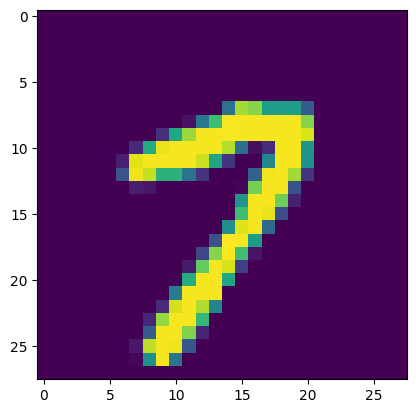

In [21]:
cc=0
plt.imshow(images_f[cc].cpu().reshape(28,28))
labels[cc]

inputs_to_inhibition


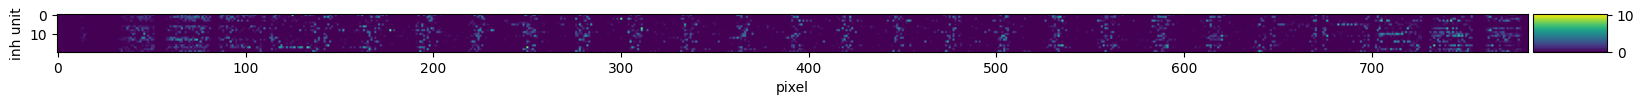

inhibition_to_dendrite_branch


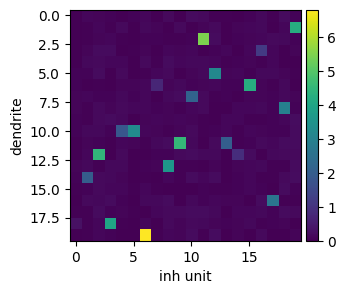

inhibition_to_dendrite_branch net


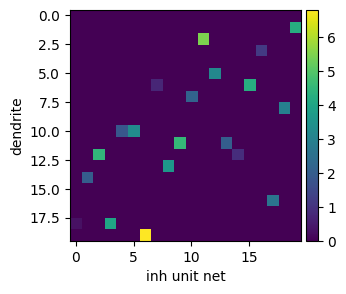

inhibition_to_dendrite_branch mask


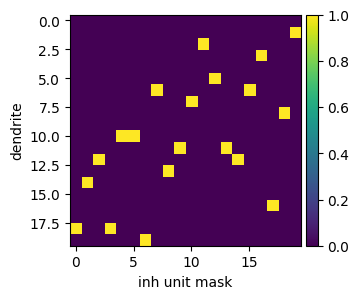

inhibition_to_dendrite


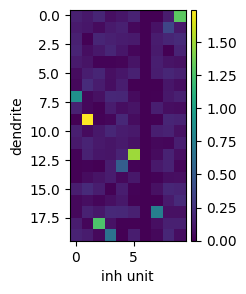

inhibition_to_dendrite net


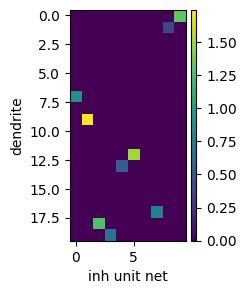

inhibition_to_dendrite mask


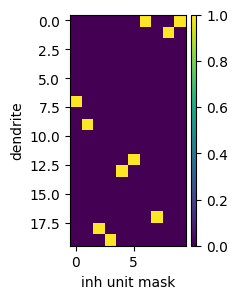

In [22]:
#@title dendrite weights
plt.rcParams["figure.figsize"] = (20,3)

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inhibition_to_dendrite_branch")
plt.xlabel("inh unit")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

print("inhibition_to_dendrite_branch net")
plt.xlabel("inh unit net")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

print("inhibition_to_dendrite_branch mask")
plt.xlabel("inh unit mask")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())

print("inhibition_to_dendrite")
plt.xlabel("inh unit")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.weight.data.t())

print("inhibition_to_dendrite net")
plt.xlabel("inh unit net")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

print("inhibition_to_dendrite mask")
plt.xlabel("inh unit mask")
plt.ylabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.mask.data.t())


dendrite_branch_to_dendrite


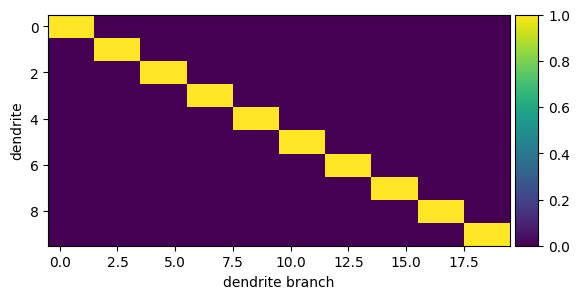

dendrites_to_soma


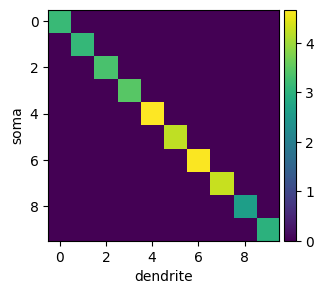

dendrites_to_soma net


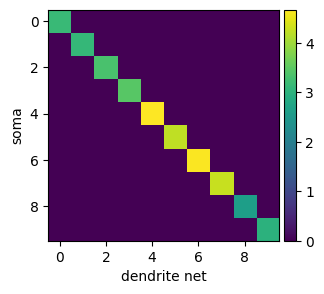

In [23]:
# #@title dendrite branch weights

plt.rcParams["figure.figsize"] = (20,3)
plt.xlabel("dendrite branch")
plt.ylabel("dendrite")
print("dendrite_branch_to_dendrite")
plotWithColor(net.dendrite_branch_to_dendrite.weight.data)

plt.rcParams["figure.figsize"] = (10,3)
plt.xlabel("dendrite")
plt.ylabel("soma")
print("dendrites_to_soma")
plotWithColor(net.dendrite_to_soma.weight.data)

plt.xlabel("dendrite net")
plt.ylabel("soma")
print("dendrites_to_soma net")
plotWithColor(net.dendrite_to_soma.net_weight.data)




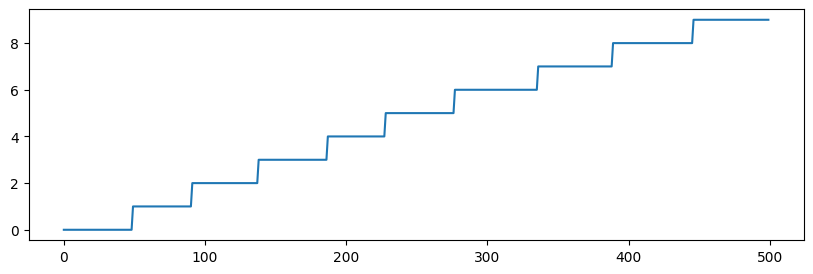

In [24]:
images_f = images.view(-1,28*28).cuda()
labels_f = labels.cuda()
images_set, labels_set, _=applyRandomFlip(images_f, labels_f, setAll=True, setValue=1)
labels_sort, labels_sort_ind=torch.sort(labels_set)
images_sort=images_set[labels_sort_ind]

with torch.no_grad():
  output=net(images_sort)


# labels_sort, labels_sort_ind=torch.sort(labels)
# images_sort=images[labels_sort_ind]
plt.plot(labels_sort.cpu().numpy())

In [25]:
output=net(images_sort.view(-1,28*28).cuda())

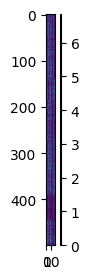

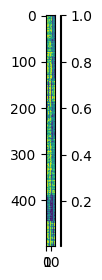

In [26]:
plt.rcParams["figure.figsize"] = (20,3)
plotWithColor(net.inhibition_v_inf)
plotWithColor(net.inhibition_out)

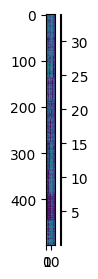

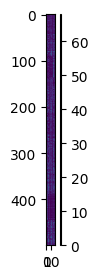

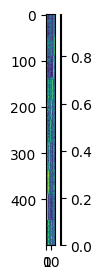

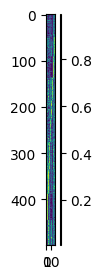

In [27]:
plotWithColor(net.dendrite_branch_inhibition)
plotWithColor(net.dendrite_branch_excitation)
plotWithColor(net.dendrite_branch_v_inf)
plotWithColor(net.dendrite_branch_out)

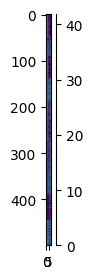

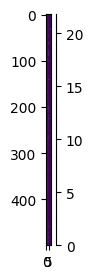

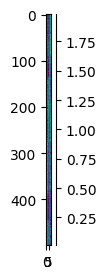

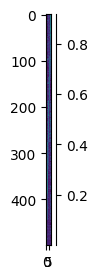

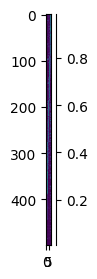

In [28]:
plotWithColor(net.dendrite_inhibition)
plotWithColor(net.dendrite_excitation)
plotWithColor(net.dendrite_depolarization)
plotWithColor(net.dendrite_v_inf)
plotWithColor(net.dendrite_out)

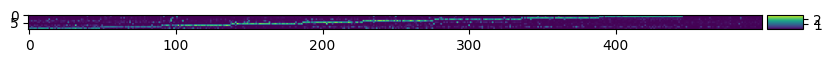

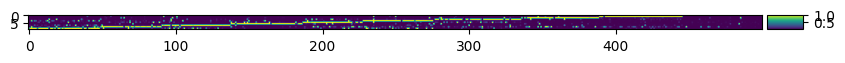

In [29]:
plt.rcParams["figure.figsize"] = (10,3)
plotWithColor(net.soma_v_inf.t())
plotWithColor(net.soma_out.t())

In [30]:
# #@title The shape of the total excitatory input to each main dendrite (sum of branches)

# for soma_counter in range(soma_n):
#   fig, axs = plt.subplots(1, dendrite_per_soma)
#   fig.set_figwidth(20)

#   for dendrite_counter in range(dendrite_per_soma):
#     imAvg=0*net.inputs_to_dendrite_branch.net_weight.data[0,:].reshape(28,28);
#     for counter in range(dendrite_branch_per_dendrite):
#       start_dendrite_branch=soma_counter*dendrite_branch_per_soma +  dendrite_counter*dendrite_branch_per_dendrite
#       imAvg+=net.inputs_to_dendrite_branch.net_weight.data[start_dendrite_branch+counter,:].reshape(28,28)
#     if dendrite_per_soma==1:
#       axs.imshow(imAvg.cpu().numpy())
#       axs.set_xlabel(dendrite_counter)
#     else:
#       axs[dendrite_counter].imshow(imAvg.cpu().numpy())
#       axs[dendrite_counter].set_xlabel(dendrite_counter)
#   if dendrite_per_soma==1:
#     axs.set_ylabel(soma_counter)
#   else:
#     axs[0].set_ylabel(soma_counter)


In [31]:
# #@title The shape of the total excitatory input directly on the main dendrites of each soma
# fig, axs = plt.subplots(1, 10)
# fig.set_figwidth(20)
# fig.suptitle('The shape of the total excitatory input to each soma', fontsize=16)

# for soma_counter in range(soma_n):
#   imAvg=0*net.inputs_to_dendrite_branch.net_weight.data[0,:].reshape(28,28);
#   for counter in range(soma_counter*dendrite_branch_per_soma, (soma_counter+1)*dendrite_branch_per_soma):
#     imAvg+=net.inputs_to_dendrite_branch.net_weight.data[counter,:].reshape(28,28)
#   axs[soma_counter].imshow(imAvg.cpu().numpy())


In [32]:
# #@title The shape of the total inhibitory input directly to the main dendrites of each soma
# inhIndices=net.inhibition_to_dendrite.topk_indices.flatten()
# fig, axs = plt.subplots(1, soma_n)
# fig.set_figwidth(20)
# for soma_index in range(soma_n):
#   imAvg=0*net.inputs_to_inhibition.weight.data[0,:].reshape(28,28);
#   for counter in range(soma_index*dendrite_per_soma, (soma_index+1)*dendrite_per_soma):
#     imAvg+=net.inputs_to_inhibition.net_weight.data[inhIndices[counter],:].reshape(28,28)
#   fig.suptitle('The shape of the total inhibitory input directly onto dendrites of each soma', fontsize=16)
#   axs[soma_index].imshow(imAvg.cpu().numpy())

# inhIndices=net.inhibition_to_dendrite_branch.topk_indices.flatten()
# fig, axs = plt.subplots(1, soma_n)
# fig.set_figwidth(20)
# for soma_index in range(soma_n):
#   imAvg=0*net.inputs_to_inhibition.weight.data[0,:].reshape(28,28);
#   for counter in range(soma_index*dendrite_branch_per_soma, (soma_index+1)*dendrite_branch_per_soma):
#     imAvg+=net.inputs_to_inhibition.net_weight.data[inhIndices[counter],:].reshape(28,28)
#   fig.suptitle('The shape of the total inhibitory input to all dendrite branches of each soma', fontsize=16)
#   axs[soma_index].imshow(imAvg.cpu().numpy())


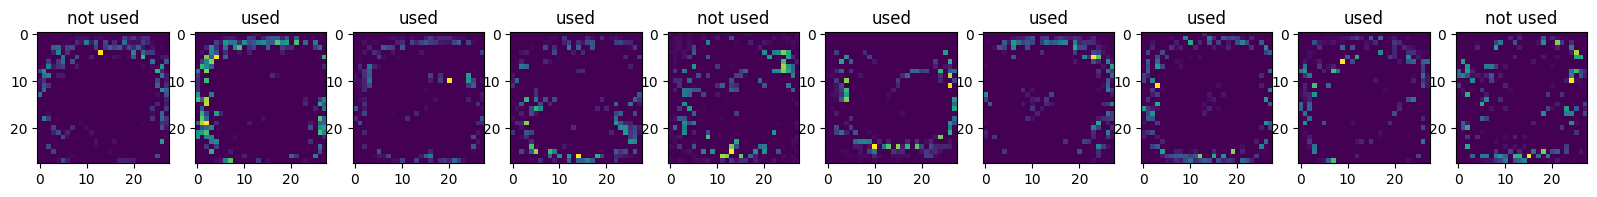

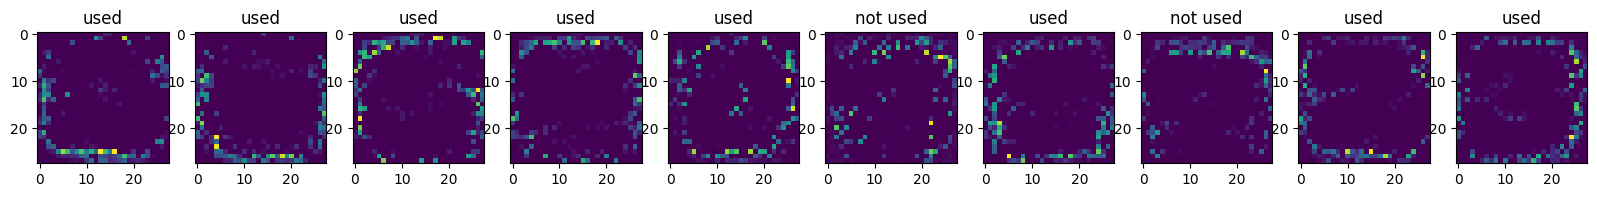

In [33]:
#@title The shape of the input to each inhibitory cell
plt.rcParams["figure.figsize"] = (20,2)
from math import ceil

inhIndices=net.inhibition_to_dendrite_branch.topk_indices.flatten()
for inh_index in range(inhibitory_units_n):
  if inh_index % 10==0:
    fig, axs = plt.subplots(1, 10)
    fig.set_figwidth(20)
    offset=inh_index

  axs[inh_index % 10].imshow(net.inputs_to_inhibition.net_weight.data[inh_index,:].reshape(28,28).cpu().numpy())
  if torch.where(inhIndices==inh_index)[0].numel()==0:
    axs[inh_index % 10].set_title('not used')
  else:
    axs[inh_index % 10].set_title('used')



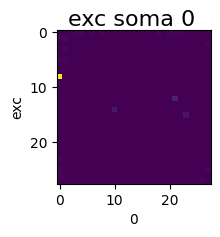

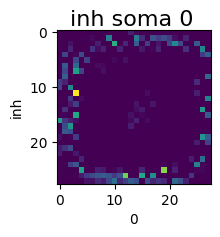

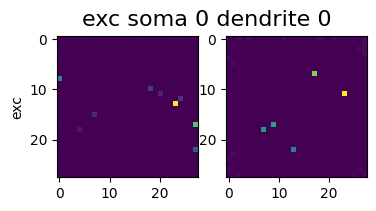

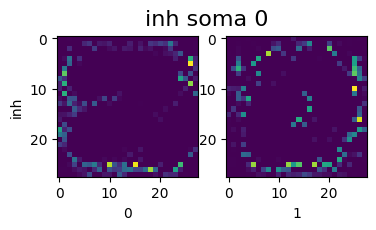

In [34]:
#@title The input onto each main dendrite and each dendrite branch
inhIndices_dendrite=net.inhibition_to_dendrite.topk_indices.flatten()
inhIndices_branch=net.inhibition_to_dendrite_branch.topk_indices.flatten()

plt.rcParams["figure.figsize"] = (20,2)

#for soma_counter in range(soma_n):
soma_counter=0

fig_dendrite_exc, axs_dendrite_exc = plt.subplots(1, dendrite_per_soma)
fig_dendrite_exc.set_figwidth(2*dendrite_per_soma)
fig_dendrite_exc.suptitle("exc soma "+str(soma_counter), fontsize=16)
if dendrite_per_soma==1:
  axs_dendrite_exc.set_ylabel('exc')
else:
  axs_dendrite_exc[0].set_ylabel('exc')

start_dendrite=soma_counter*dendrite_per_soma

for dendrite_counter in range(dendrite_per_soma):
  exc_data=net.inputs_to_dendrite.net_weight.data[start_dendrite+dendrite_counter,:].reshape(28,28).cpu().numpy()
  if dendrite_per_soma==1:
    axs_dendrite_exc.imshow(exc_data)
    axs_dendrite_exc.set_xlabel(dendrite_counter)
  else:
    axs_dendrite_exc[dendrite_counter].imshow(exc_data)
    axs_dendrite_exc[dendrite_counter].set_xlabel(dendrite_counter)

total_inh=dendrite_per_soma*inhibitory_synapses_per_dendrite
fig_dendrite_inh, axs_dendrite_inh = plt.subplots(1, total_inh)
fig_dendrite_inh.set_figwidth(2*total_inh)
fig_dendrite_inh.suptitle("inh soma "+str(soma_counter), fontsize=16)
if total_inh==1:
  axs_dendrite_inh.set_ylabel('inh')
else:
  axs_dendrite_inh[0].set_ylabel('inh')

for inh_counter in range(total_inh):
  inh_data=net.inputs_to_inhibition.weight.data[inhIndices_dendrite[start_dendrite*inhibitory_synapses_per_dendrite+inh_counter],:].reshape(28,28).cpu().numpy()
  if total_inh==1:
    axs_dendrite_inh.imshow(inh_data)
    axs_dendrite_inh.set_xlabel(dendrite_counter)
  else:
    axs_dendrite_inh[inh_counter].imshow(inh_data)
    axs_dendrite_inh[inh_counter].set_xlabel(dendrite_counter)

  start_dendrite_branch=soma_counter*dendrite_branch_per_soma +  dendrite_counter*dendrite_branch_per_dendrite

  fig_branches_exc, axs_branches_exc = plt.subplots(1, dendrite_branch_per_dendrite)
  fig_branches_exc.set_figwidth(2*dendrite_branch_per_dendrite)
  fig_branches_exc.suptitle("exc soma "+str(soma_counter)+" dendrite "+str(dendrite_counter), fontsize=16)
  axs_branches_exc[0].set_ylabel('exc')

  for counter in range(dendrite_branch_per_dendrite):
    imCurrent=net.inputs_to_dendrite_branch.net_weight.data[start_dendrite_branch+counter,:].reshape(28,28).cpu().numpy()
    axs_branches_exc[counter].imshow(imCurrent)

  total_inh=dendrite_branch_per_dendrite*inhibitory_synapses_per_dendrite
  fig_branches_inh, axs_branches_inh = plt.subplots(1, total_inh)
  fig_branches_inh.set_figwidth(2*total_inh)
  fig_branches_inh.suptitle("inh soma "+str(soma_counter), fontsize=16)
  if total_inh==1:
    axs_branches_inh.set_ylabel('inh')
  else:
    axs_branches_inh[0].set_ylabel('inh')

  for inh_counter in range(total_inh):
    inh_data=net.inputs_to_inhibition.weight.data[inhIndices[start_dendrite_branch*inhibitory_synapses_per_dendrite+inh_counter],:].reshape(28,28).cpu().numpy()

    if total_inh==1:
      axs_branches_inh.imshow(inh_data)
      axs_branches_inh.set_xlabel(dendrite_counter)
    else:
      axs_branches_inh[inh_counter].imshow(inh_data)
      axs_branches_inh[inh_counter].set_xlabel(inh_counter)

  #   imCurrent=net.inputs_to_inhibition.net_weight.data[inhIndices[start_dendrite_branch+counter],:].reshape(28,28)
  #   axs_branches[1, counter].imshow(imCurrent.cpu().numpy())
  #   axs_branches[1, counter].set_xlabel(counter)


  # axs_branches[1, 0].set_ylabel('inh')



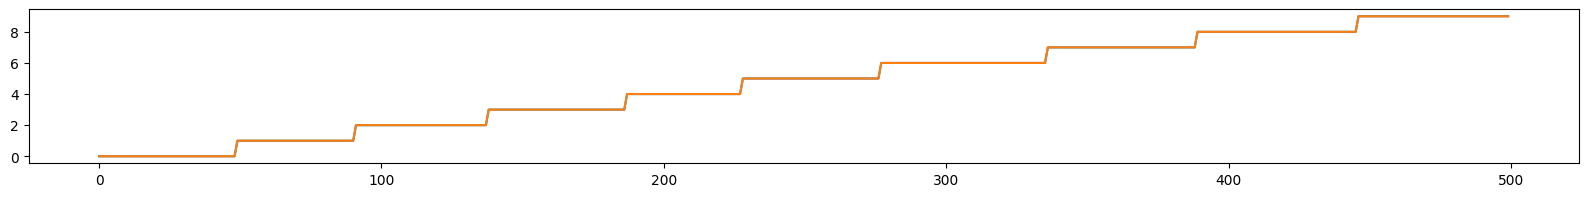

In [35]:

images_f = images.view(-1,28*28).cuda()
labels_f = labels.cuda()
images_set, labels_set, _=applyRandomFlip(images_f, labels_f, setAll=True, setValue=0)
labels_sort, labels_sort_ind=torch.sort(labels_set)
images_sort=images_set[labels_sort_ind]

with torch.no_grad():
  output=net(images_sort)

inh_v_inf_0=net.inhibition_v_inf.t().cpu()
inh_out_0=net.inhibition_out.t().cpu()
den_inh_0=net.dendrite_inhibition.cpu()
den_exc_0=net.dendrite_excitation.cpu()
den_v_inf_0=net.dendrite_v_inf.cpu()

images, labels, _=applyRandomFlip(images_f, labels_f, setAll=True, setValue=1)
labels_sort, labels_sort_ind=torch.sort(labels)
images_sort=images[labels_sort_ind]

with torch.no_grad():
  output=net(images_sort)

inh_v_inf_1=net.inhibition_v_inf.t().cpu()
inh_out_1=net.inhibition_out.t().cpu()
den_inh_1=net.dendrite_inhibition.cpu()
den_exc_1=net.dendrite_excitation.cpu()
den_v_inf_1=net.dendrite_v_inf.cpu()

plt.plot(labels_sort.cpu().numpy())
plt.plot(labels_sort.cpu().numpy())

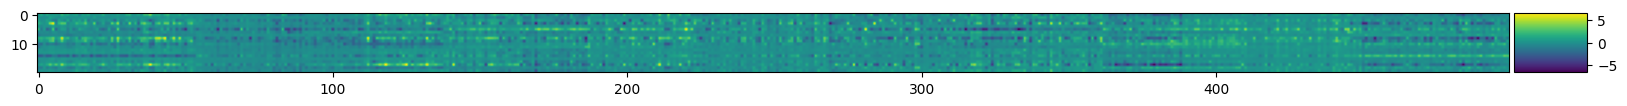

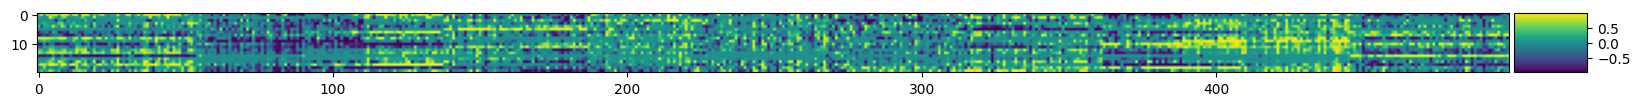

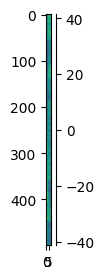

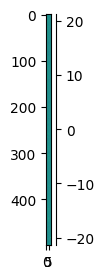

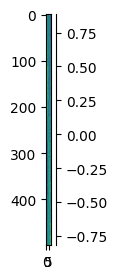

In [36]:
plt.rcParams["figure.figsize"] = (20,3)
plotWithColor(inh_v_inf_0-inh_v_inf_1)
plotWithColor(inh_out_0-inh_out_1)
plotWithColor(den_inh_0-den_inh_1)
plotWithColor(den_exc_0-den_exc_1)
plotWithColor(den_v_inf_0-den_v_inf_1)